Załadowanie datasetu, potrzebnych bibliotek

In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('../data/solar_dataset_tauron.csv')
print(df.info())
print(f"{'-'*10} Kolumny{'-'*10}\n\n")
print(df.columns)

<class 'pandas.DataFrame'>
RangeIndex: 17544 entries, 0 to 17543
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   timestamp        17544 non-null  str    
 1   date             17544 non-null  str    
 2   hour             17544 non-null  int64  
 3   day_of_year      17544 non-null  int64  
 4   month            17544 non-null  int64  
 5   uv_index         17544 non-null  float64
 6   cloud_cover_pct  17544 non-null  float64
 7   sunshine_pct     17544 non-null  float64
 8   temperature_c    17544 non-null  float64
 9   wind_speed_ms    17544 non-null  float64
 10  humidity_pct     17544 non-null  float64
 11  pressure_hpa     17544 non-null  float64
 12  production_mwh   17544 non-null  float64
dtypes: float64(8), int64(3), str(2)
memory usage: 1.7 MB
None
---------- Kolumny----------


Index(['timestamp', 'date', 'hour', 'day_of_year', 'month', 'uv_index',
       'cloud_cover_pct', 'sunshine_pct', 'tem

Data enginiering - podmianka typow

In [4]:
#daty
df.index = pd.to_datetime(df.index)
df['date'] = pd.to_datetime(df['date'])


print(df[['date']].head())
print(df[['date']].dtypes)

# trzeba zrobic daty cyklicznie inaczej model sie nie skampie bedzeie myslal ze np 12 (grudzien) nie jest przed styczniem
df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)

df['day_sin']  = np.sin(2 * np.pi * df['day_of_year'] / 365)
df['day_cos']  = np.cos(2 * np.pi * df['day_of_year'] / 365)

df['month_sin']  = np.sin(2 * np.pi * df['month'] / 365)
df['month_cos']  = np.cos(2 * np.pi * df['month'] / 365)

#reszta ok tylko produkcja by byla ostatnia

a = [x for x in df.columns if x != 'production_mwh']
b = a + ['production_mwh']
df = df[b]
print(df.columns)


                                    date
1970-01-01 00:00:00.000000000 2023-01-01
1970-01-01 00:00:00.000000001 2023-01-01
1970-01-01 00:00:00.000000002 2023-01-01
1970-01-01 00:00:00.000000003 2023-01-01
1970-01-01 00:00:00.000000004 2023-01-01
date    datetime64[us]
dtype: object
Index(['timestamp', 'date', 'hour', 'day_of_year', 'month', 'uv_index',
       'cloud_cover_pct', 'sunshine_pct', 'temperature_c', 'wind_speed_ms',
       'humidity_pct', 'pressure_hpa', 'hour_sin', 'hour_cos', 'day_sin',
       'day_cos', 'month_sin', 'month_cos', 'production_mwh'],
      dtype='str')


Heatmapa korelacji spearmana - powiazania pomiedzy naszymi danymi, badami zaleznosci monotoniczne,
czy jezeli jedna wartosc rosnie to czy wplywa to na
Działanie: wynik w granicy -1 do 1, 0 oznacza brak korelacji
Sperman zamienia wartosci na rangi i sprawdza jak razem oddzialuja na inne wartosci

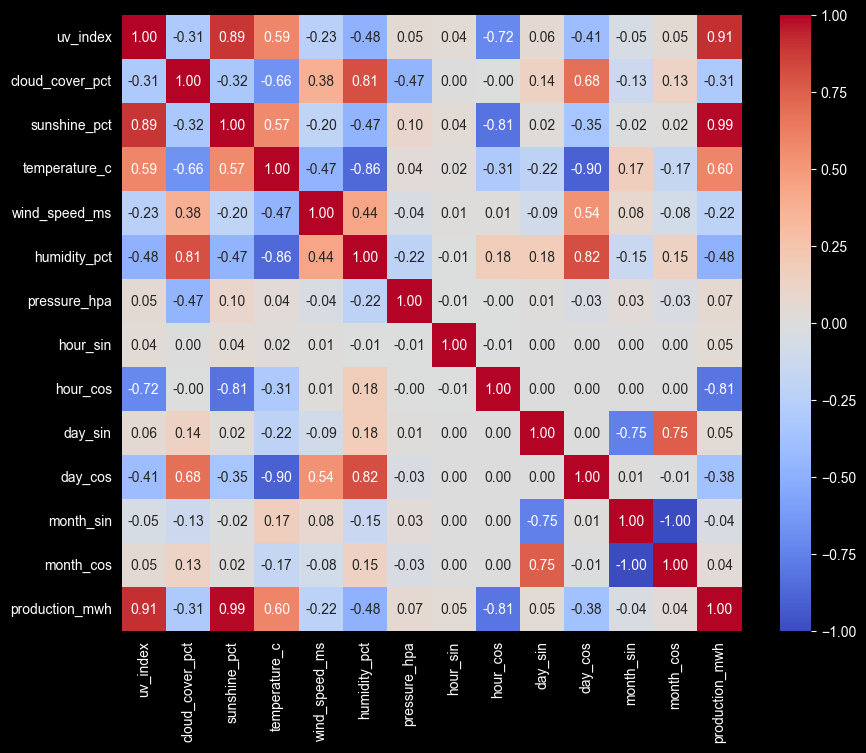

In [13]:

test=df.iloc[:,5:]
# Wymaga dataframe 'df' tylko z kolumnami numerycznymi
corr_matrix = test.corr(method='spearman', numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.show() # lub plt.savefig('nazwa.png')

histogramy wartosci

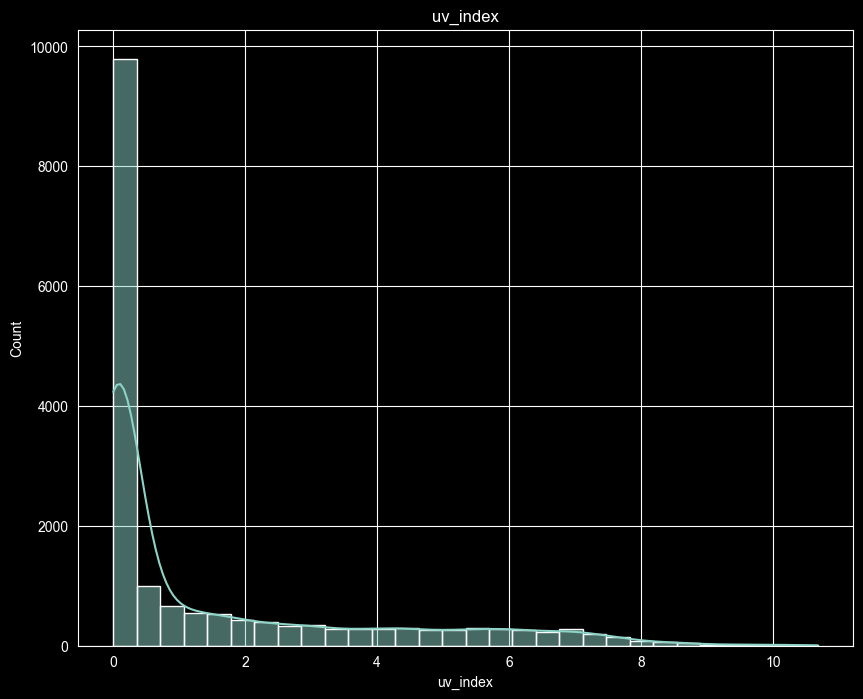

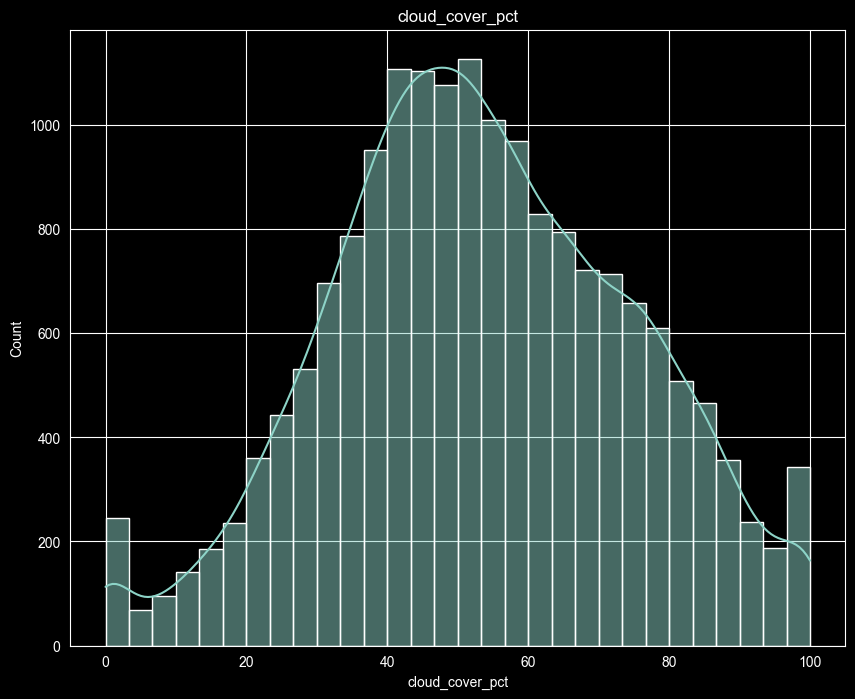

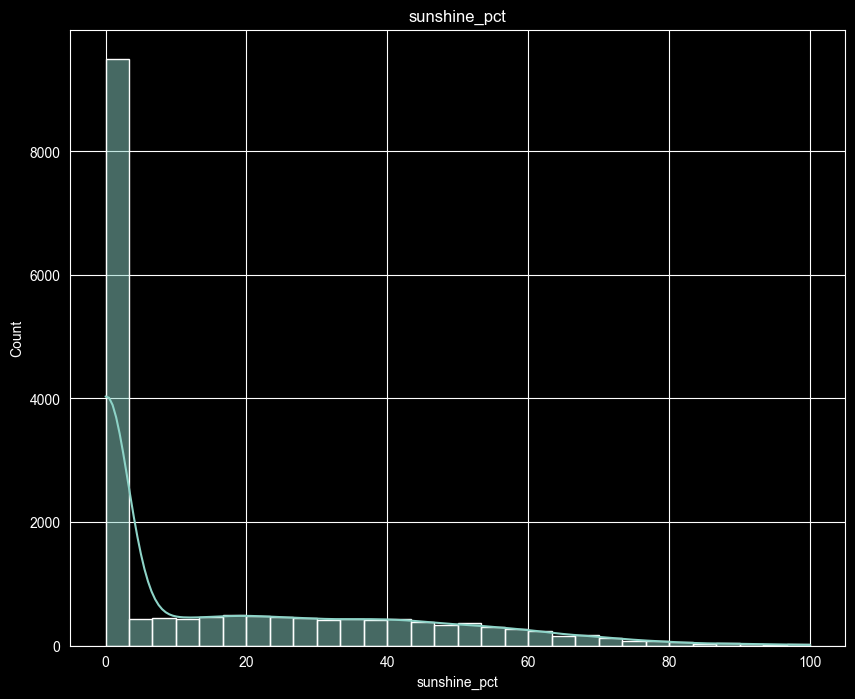

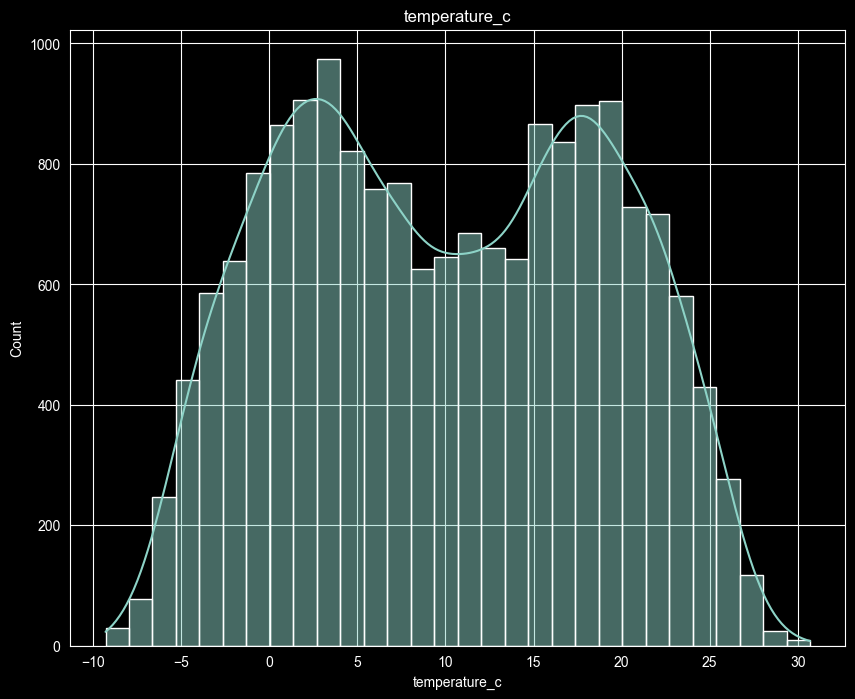

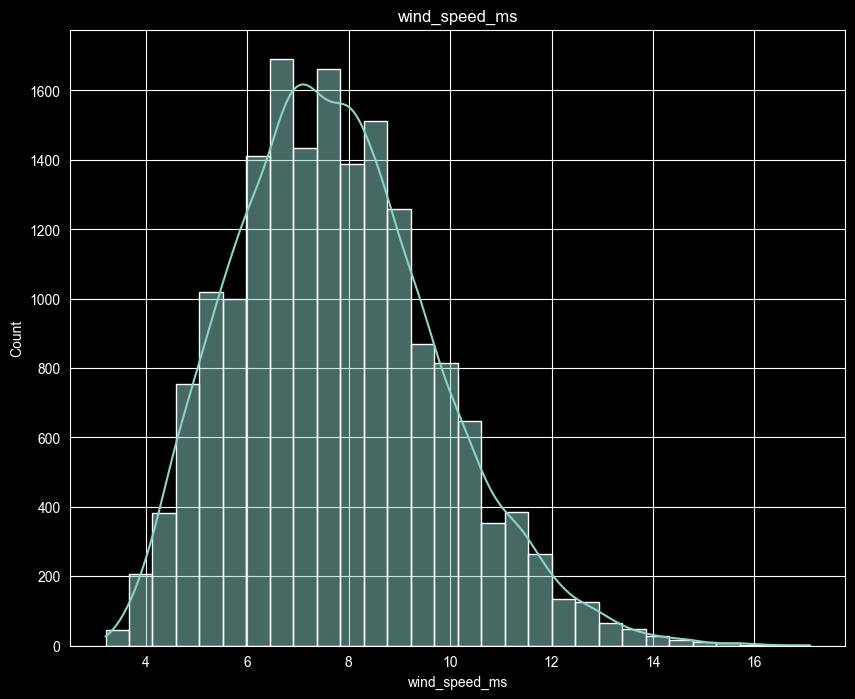

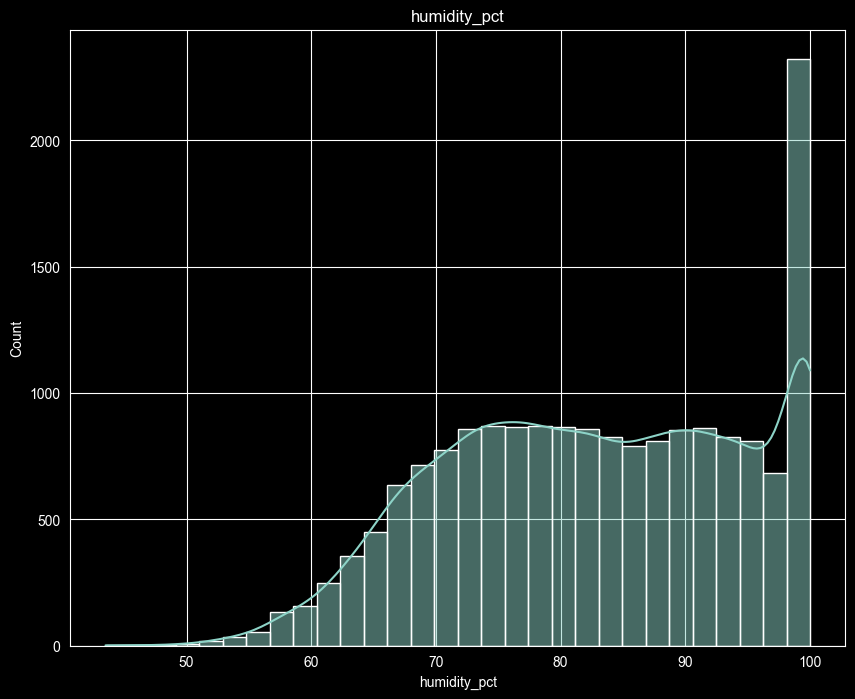

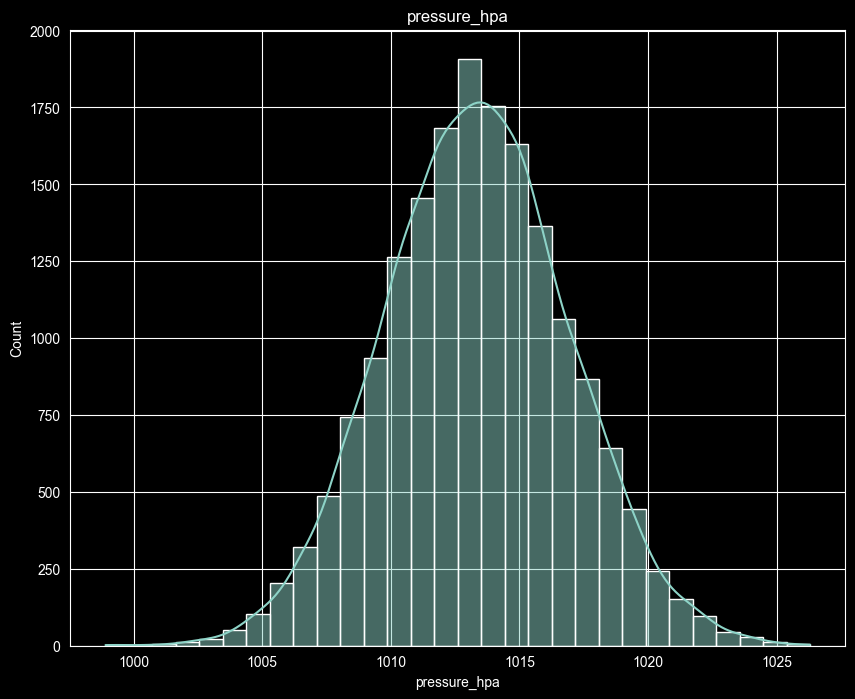

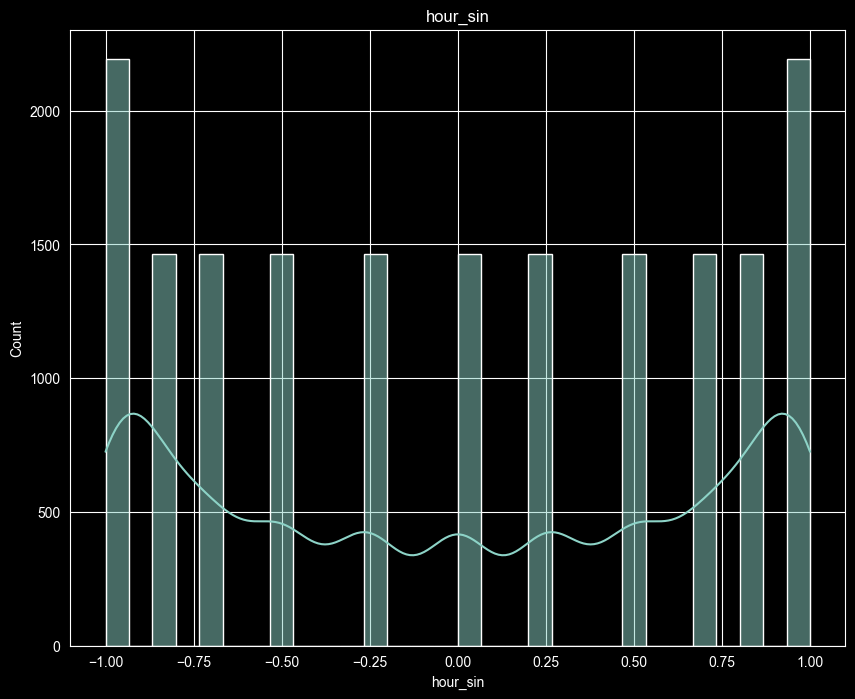

In [6]:
kolumny_z_danymi = df.columns[5:13]
for k in kolumny_z_danymi:
    plt.figure(figsize=(10, 8))
    sns.histplot(df[k], bins=30, kde=True)
    plt.title(f'{k}')
    plt.show()
    plt.close()

histogramy przedstawiajacy rozlozenie najwazniejszych danych na dany miesiac/godziny

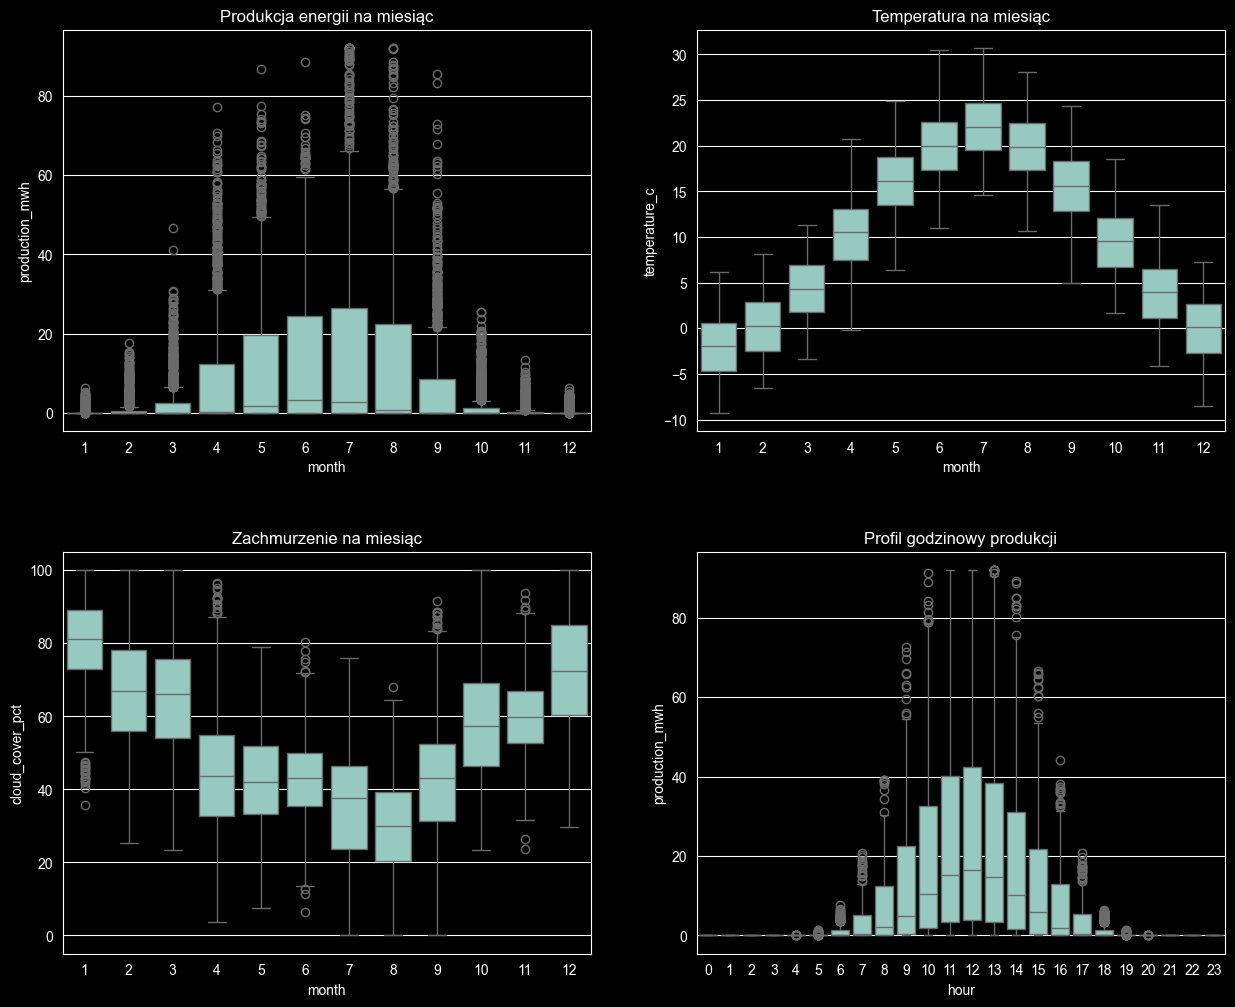

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
plt.subplots_adjust(hspace=0.3)


# Lewy górny: Produkcja na miesiąc
sns.boxplot(data=df, x='month', y='production_mwh', ax=axes[0, 0])
axes[0, 0].set_title("Produkcja energii na miesiąc")

# Prawy górny: Temperatura na miesiąc
sns.boxplot(data=df, x='month', y='temperature_c', ax=axes[0, 1])
axes[0, 1].set_title("Temperatura na miesiąc")

# Lewy dolny: Zachmurzenie na miesiąc
sns.boxplot(data=df, x='month', y='cloud_cover_pct', ax=axes[1, 0])
axes[1, 0].set_title("Zachmurzenie na miesiąc")

# Prawy dolny: Produkcja na godzina
sns.boxplot(data=df, x='hour', y='production_mwh', ax=axes[1, 1])
axes[1, 1].set_title("Profil godzinowy produkcji")

# 4. Wyświetlenie
plt.show()

wykres produkcji

timestamp
2023-01-31     213.097
2023-02-28     589.339
2023-03-31    1519.520
2023-04-30    4909.687
2023-05-31    9370.602
Freq: ME, Name: production_mwh, dtype: float64


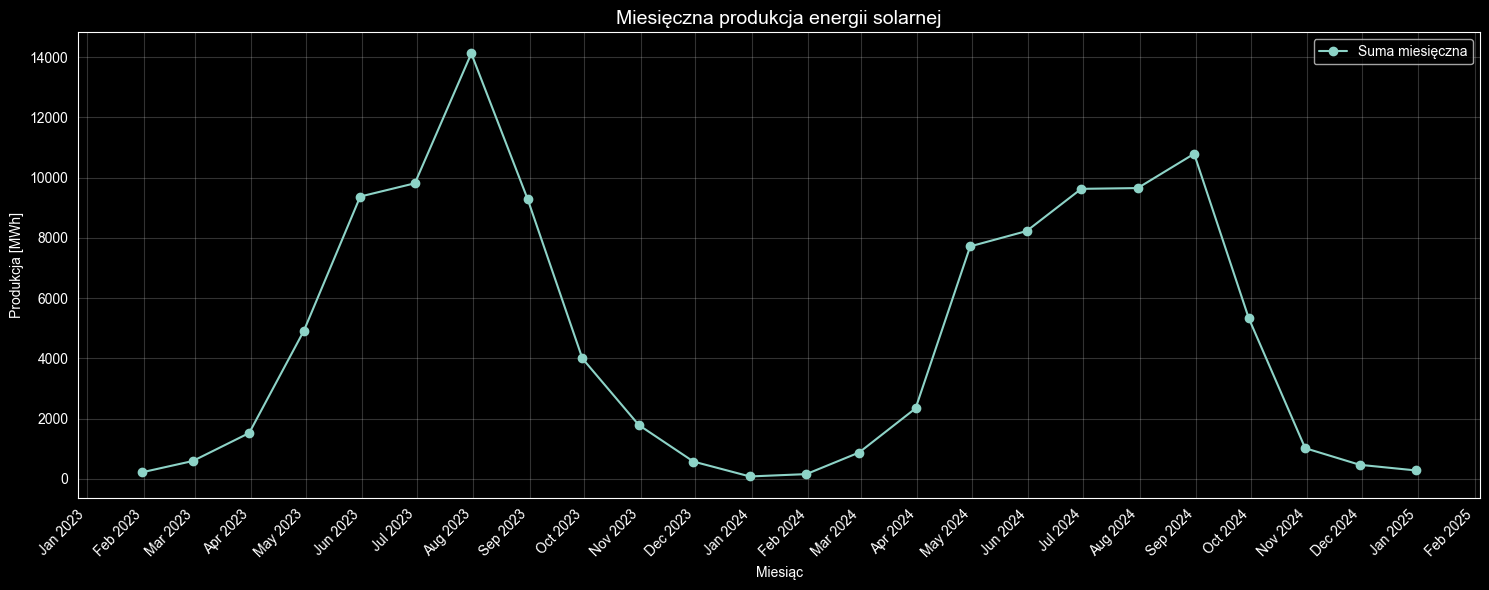

In [8]:
import matplotlib.dates as mdates

df['timestamp'] = pd.to_datetime(df['timestamp'])

df_monthly = df.set_index('timestamp').resample('ME')['production_mwh'].sum()

print(df_monthly.head())

plt.figure(figsize=(15, 6))

plt.plot(df_monthly.index, df_monthly.values, marker='o', label='Suma miesięczna')

plt.title('Miesięczna produkcja energii solarnej', fontsize=14)
plt.xlabel('Miesiąc')
plt.ylabel('Produkcja [MWh]')
plt.grid(True, alpha=0.2)
plt.legend()

# formatowanie osi X — pokazuje skrót miesiąca i rok
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

missing heatmap

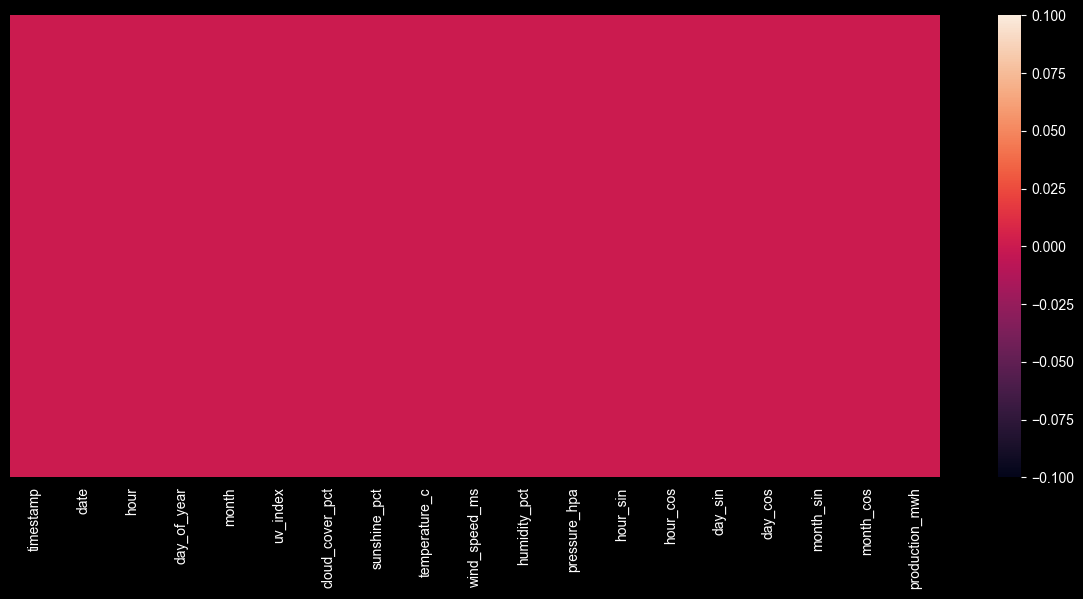

In [9]:
plt.figure(figsize=(15, 6))
sns.heatmap(df.isnull(), yticklabels=False)
plt.show()

rozklad zmiennej odp: jak czesto jakie wartosci sie pojawiaja
Rozklad produkacji: ile godzin mialo jaka produkcje
Rozklad produkcji godzin dziennych: to samo tylko gdy rpodukcja > 0
Mape vs mae: tez rmse jak bedziemy miezyli blad w modelu

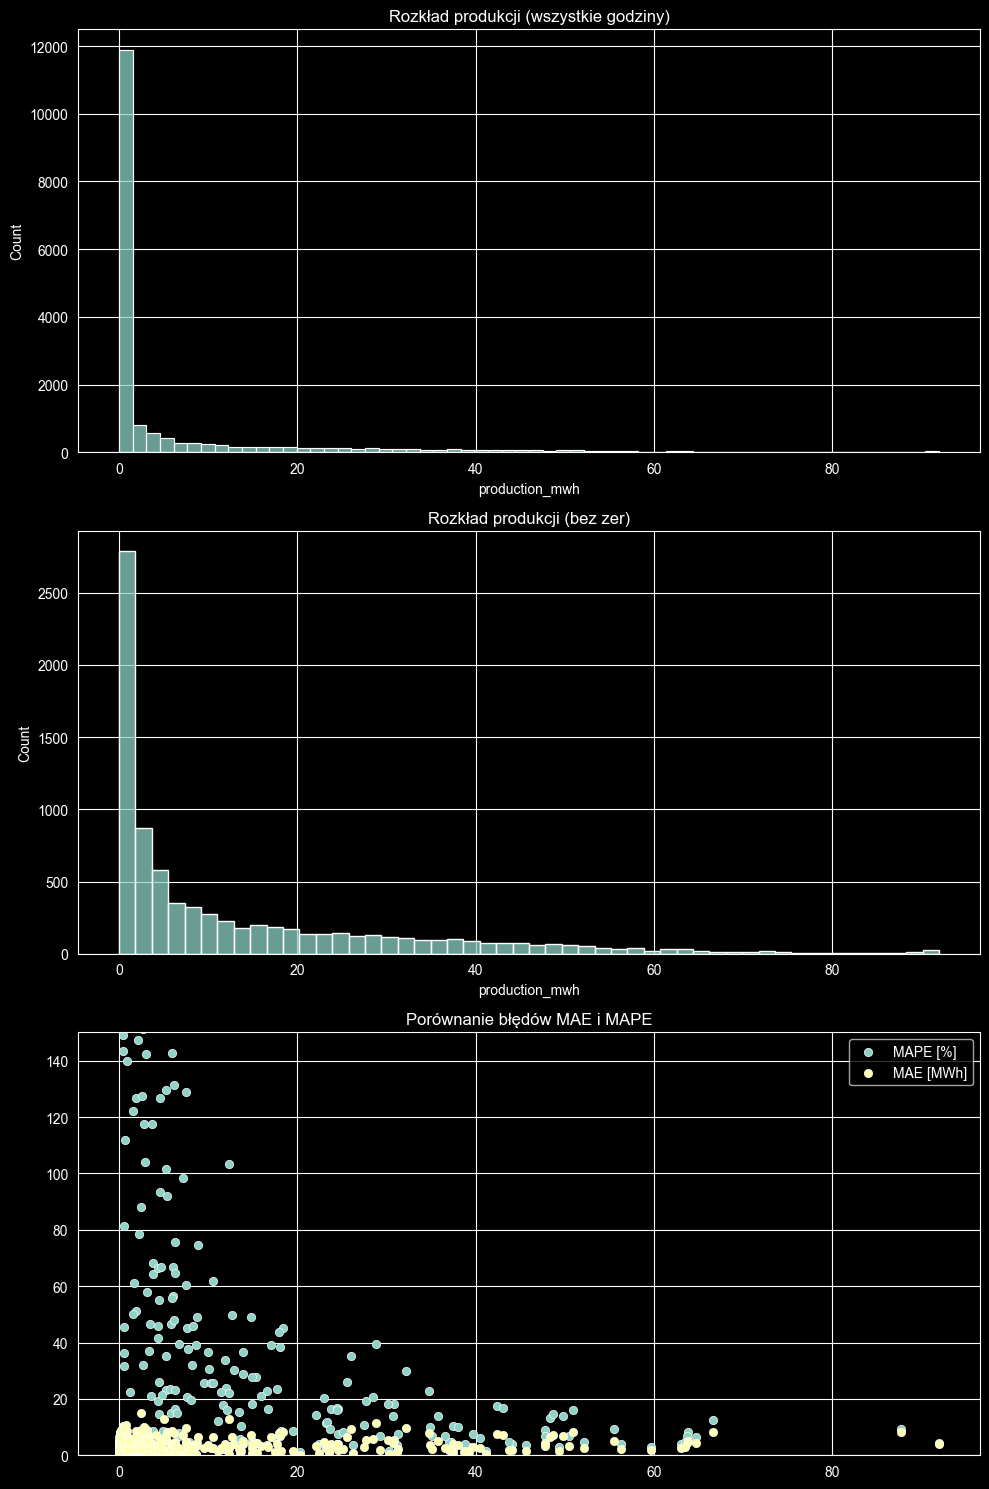

Procent zer (noc): 53.0%
Średnia (dzień): 13.65 MWh
Mediana (dzień): 5.11 MWh


In [10]:

day_only = df[df['production_mwh'] > 0]['production_mwh']
fig, axes = plt.subplots(3, 1, figsize=(10, 15))

# wszystkie dane
sns.histplot(df['production_mwh'], bins=60, ax=axes[0])
axes[0].set_title("Rozkład produkcji (wszystkie godziny)")

# godziny dzienne
sns.histplot(day_only, bins=50, ax=axes[1])
axes[1].set_title("Rozkład produkcji (bez zer)")

# MAE vs MAPE (symulacja błędu)
sample = day_only.sample(300, random_state=42).values
error = np.random.normal(0, 5, 300)
mae = np.abs(error)
mape = (mae / (sample + 1e-6)) * 100

sns.scatterplot(x=sample, y=mape, ax=axes[2], label='MAPE [%]')
sns.scatterplot(x=sample, y=mae, ax=axes[2], label='MAE [MWh]')
axes[2].set_title("Porównanie błędów MAE i MAPE")
axes[2].set_ylim(0, 150)

plt.tight_layout()
plt.show()

# statystyka
print(f"Procent zer (noc): {(df['production_mwh'] == 0).mean()*100:.1f}%")
print(f"Średnia (dzień): {day_only.mean():.2f} MWh")
print(f"Mediana (dzień): {day_only.median():.2f} MWh")

wnioski przerzemy albo mae (mean absolute error) albo raczej rmse (root mean square error)
mae - srednia wszystkich bledow
rmse - wali wieksza kare za duze pomylki - pierwsiatek z sredniej sumy pomylek

sprawdzenie lagów czyli czy lepie patrzec sie tylko jedna godzine 24 h do tylko czy moze brac pod uwage cale ostatnie 24 h

ACF - auto correlation function, mierzy korelację z każdym lagiem, włącznie z efektami pośrednimi. Jeśli produkcja wczoraj koreluje z przedwczoraj, a przedwczoraj z dzisiaj — ACF to wszystko zsumuje.

PACF - partial auto correlation function -  mierzy korelację z danym lagiem po odjęciu wpływu wszystkich lagów pośrednich. Pyta: "czy lag 48h wnosi coś nowego ponad to co już wiemy z lagu 24h?"

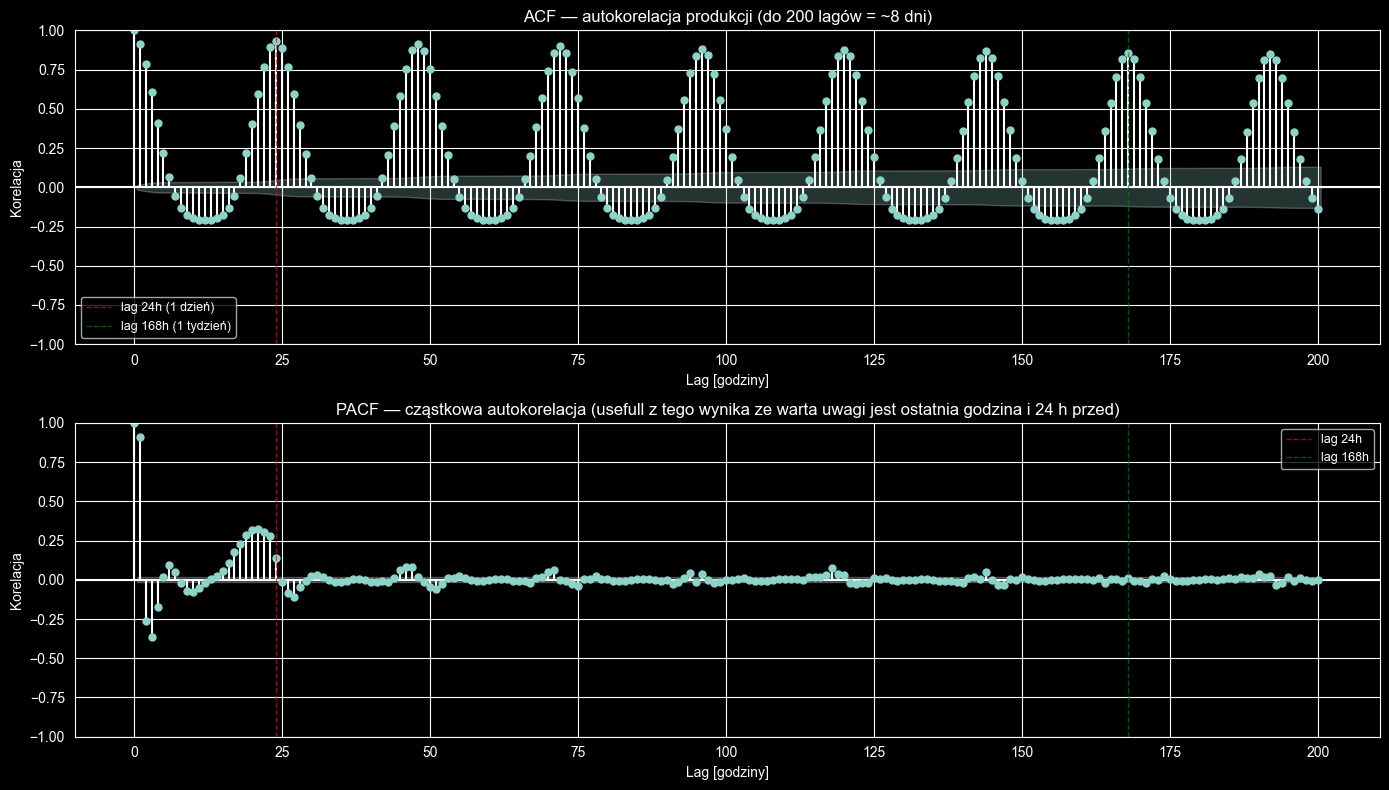

In [11]:
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

# POPRAWKA: zostaw pełny szereg z zerami — ciągłość czasowa musi być zachowana
production = df['production_mwh'].reset_index(drop=True)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8))

plot_acf(production, lags=200, ax=ax1)
ax1.set_title('ACF — autokorelacja produkcji (do 200 lagów = ~8 dni)')
ax1.set_xlabel('Lag [godziny]')
ax1.set_ylabel('Korelacja')

# zaznacz ważne lagi
ax1.axvline(x=24,  color='red',    linewidth=1, linestyle='--', alpha=0.7, label='lag 24h (1 dzień)')
ax1.axvline(x=168, color='green',  linewidth=1, linestyle='--', alpha=0.7, label='lag 168h (1 tydzień)')
ax1.legend(fontsize=9)

plot_pacf(production, lags=200, ax=ax2, method='ywm')
ax2.set_title('PACF — cząstkowa autokorelacja (usefull z tego wynika ze warta uwagi jest ostatnia godzina i 24 h przed)')
ax2.set_xlabel('Lag [godziny]')
ax2.set_ylabel('Korelacja')

ax2.axvline(x=24,  color='red',   linewidth=1, linestyle='--', alpha=0.7, label='lag 24h')
ax2.axvline(x=168, color='green', linewidth=1, linestyle='--', alpha=0.7, label='lag 168h')
ax2.legend(fontsize=9)

plt.tight_layout()
plt.show()